In [19]:
import pandas as pd

In [20]:
df=pd.read_csv('insurance_data.csv')
df.head()

,age,has_insurance
0,18,0
1,19,0
2,20,0
3,22,0
4,23,0


In [21]:
X=df[['age']]
y=df.has_insurance

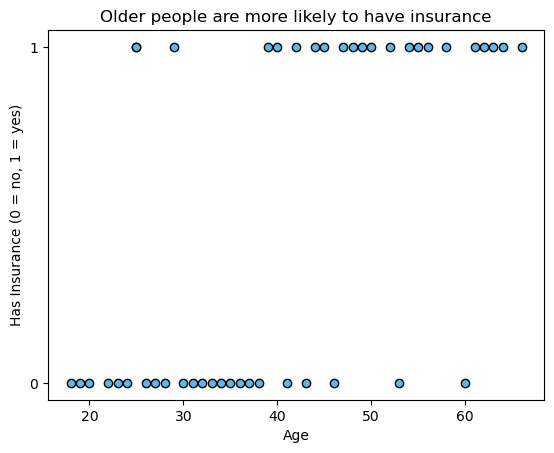

In [22]:
import matplotlib.pyplot as plt

plt.scatter(df.age, df.has_insurance, color='#5BB8E8', edgecolor='k')
plt.xlabel("Age")
plt.ylabel("Has Insurance (0 = no, 1 = yes)")
plt.title("Older people are more likely to have insurance")
plt.yticks([0, 1])
plt.show()

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=43)
model=LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

In [24]:
ages=pd.DataFrame({"age":[23,46,70]})

In [25]:
predicts=model.predict(ages)
predicts

array([0, 1, 1], dtype=int64)

In [26]:
probability=model.predict_proba(ages)
probability

array([[0.92750644, 0.07249356],
       [0.32220061, 0.67779939],
       [0.01507517, 0.98492483]])

In [27]:
accuracy=model.score(X_test,y_test)
accuracy

0.6666666666666666

In [28]:
from sklearn.metrics import classification_report
y_pred=model.predict(X_test)
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.67      0.80      0.73         5
           1       0.67      0.50      0.57         4

    accuracy                           0.67         9
   macro avg       0.67      0.65      0.65         9
weighted avg       0.67      0.67      0.66         9



In [29]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[4 1]
 [2 2]]


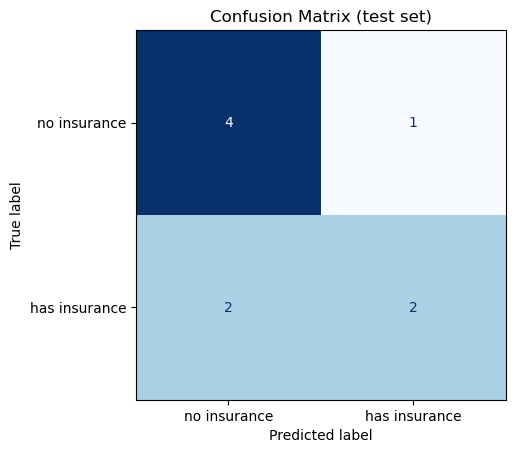

In [43]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['no insurance', 'has insurance']
)
disp.plot(cmap='Blues', colorbar=False)
plt.title('Confusion Matrix (test set)')
plt.show()

Multiclass Logistic Regression with flower dataset

In [31]:
import pandas as pd
from sklearn.datasets import load_iris

In [32]:
iris=load_iris(as_frame=True)
df=iris.frame.copy()
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [33]:
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target']
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [34]:
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df = df.drop(columns=['target'])
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [35]:
df.species.value_counts()

setosa        50
versicolor    50
virginica     50
Name: species, dtype: int64

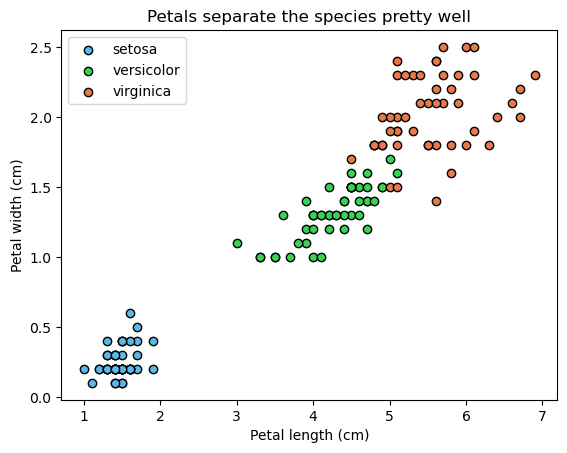

In [36]:
import matplotlib.pyplot as plt

colors = {'setosa': '#5BB8E8', 'versicolor': '#39D353', 'virginica': '#E8794B'}
for name, group in df.groupby('species'):
    plt.scatter(group.petal_length, group.petal_width,
                color=colors[name], edgecolor='k', label=name)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petals separate the species pretty well")
plt.legend()
plt.show()

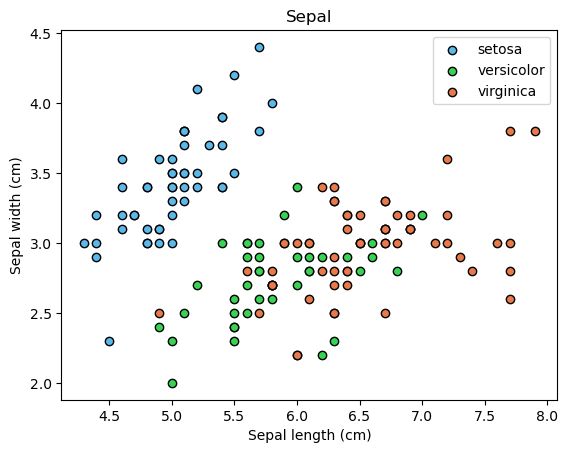

In [37]:
colors = {'setosa': '#5BB8E8', 'versicolor': '#39D353', 'virginica': '#E8794B'}
for name, group in df.groupby('species'):
    plt.scatter(group.sepal_length, group.sepal_width,
                color=colors[name], edgecolor='k', label=name)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Sepal")
plt.legend()
plt.show()

In [38]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[features]
y = df.species

print("X shape:", X.shape)
print("Classes:", list(y.unique()))

X shape: (150, 4)
Classes: ['setosa', 'versicolor', 'virginica']


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=11
)

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 120
Testing rows:  30


In [40]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

print("Learned classes:", model.classes_)

Learned classes: ['setosa' 'versicolor' 'virginica']


In [41]:
y_pred = model.predict(X_test)

compare = pd.DataFrame({'actual': y_test.values, 'predicted': y_pred})
compare.head(10)

,actual,predicted
0,virginica,virginica
1,virginica,virginica
2,virginica,versicolor
3,versicolor,versicolor
4,virginica,virginica
5,setosa,setosa
6,versicolor,versicolor
7,setosa,setosa
8,setosa,setosa
9,versicolor,versicolor


In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.82      0.90        11

    accuracy                           0.93        30
   macro avg       0.94      0.94      0.94        30
weighted avg       0.94      0.93      0.93        30

